In [3]:
import pandas as pd
import numpy as np

file = '/content/EduPro Online Platform.xlsx'

excel = pd.ExcelFile(file)

print("PROJECT DATASET LOADED SUCCESSFULLY!")
print("\nAvailable Sheets:")

for sheet in excel.sheet_names:
    df = pd.read_excel(file, sheet_name=sheet)
    print("\nSheet:", sheet)
    print("Rows and Columns:", df.shape)
    print("Column Names:", list(df.columns))
    display(df.head(3))
    file = '/content/EduPro Online Platform (1).xlsx'

FileNotFoundError: [Errno 2] No such file or directory: '/content/EduPro Online Platform.xlsx'

In [4]:
import os
print (os.listdir('/content'))

['.config', 'EduPro Online Platform (1).xlsx', 'sample_data']


In [5]:
import pandas as pd

file = '/content/EduPro Online Platform (1).xlsx'

excel = pd.ExcelFile(file)

print("PROJECT DATASET LOADED SUCCESSFULLY!")
print("Available sheets:", excel.sheet_names)

PROJECT DATASET LOADED SUCCESSFULLY!
Available sheets: ['Users', 'Teachers', 'Courses', 'Transactions']


In [6]:
import pandas as pd

df = pd.read_excel(file)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (3000, 5)

Column Names:
['UserID', 'UserName', 'Age', 'Gender', 'Email']

First 5 Rows:


,UserID,UserName,Age,Gender,Email
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com
1,U00002,angela22,29,Female,hallrandy@hotmail.com
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com
3,U00004,fthornton,23,Female,christensencatherine@outlook.com
4,U00005,fostergeoffrey,21,Male,karenfuentes@yahoo.com


In [7]:
for sheet in excel.sheet_names:
    data = pd.read_excel(file, sheet_name=sheet)
    print("\nSheet:", sheet)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())


Sheet: Users
Shape: (3000, 5)
Columns: ['UserID', 'UserName', 'Age', 'Gender', 'Email']

Sheet: Teachers
Shape: (60, 7)
Columns: ['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise', 'YearsOfExperience', 'TeacherRating']

Sheet: Courses
Shape: (60, 8)
Columns: ['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

Sheet: Transactions
Shape: (10000, 7)
Columns: ['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']


In [8]:
users = pd.read_excel(file, sheet_name='Users')
teachers = pd.read_excel(file, sheet_name='Teachers')
courses = pd.read_excel(file, sheet_name='Courses')
transactions = pd.read_excel(file, sheet_name='Transactions')

print("USERS DATA")
display(users.head(3))

print("COURSES DATA")
display(courses.head(3))

print("TRANSACTIONS DATA")
display(transactions.head(3))

USERS DATA


,UserID,UserName,Age,Gender,Email
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com
1,U00002,angela22,29,Female,hallrandy@hotmail.com
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com


COURSES DATA


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85


TRANSACTIONS DATA


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040


In [9]:
 for name, data in {
    "USERS": users,
    "TEACHERS": teachers,
    "COURSES": courses,
    "TRANSACTIONS": transactions
}.items():
    print("\n", name)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Missing Values:", data.isnull().sum().sum())


 USERS
Shape: (3000, 5)
Columns: ['UserID', 'UserName', 'Age', 'Gender', 'Email']
Missing Values: 0

 TEACHERS
Shape: (60, 7)
Columns: ['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise', 'YearsOfExperience', 'TeacherRating']
Missing Values: 0

 COURSES
Shape: (60, 8)
Columns: ['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']
Missing Values: 0

 TRANSACTIONS
Shape: (10000, 7)
Columns: ['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']
Missing Values: 0


In [10]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Student transaction details
student_data = transactions.groupby('UserID').agg(
    Purchase_Count=('TransactionID', 'count'),
    Total_Spent=('Amount', 'sum'),
    Unique_Courses=('CourseID', 'nunique'),
    Average_Spending=('Amount', 'mean')
).reset_index()

# Combine with user details
student_data = users.merge(student_data, on='UserID', how='left')

# Fill missing values
student_data = student_data.fillna(0)

# Select features
features = [
    'Purchase_Count',
    'Total_Spent',
    'Unique_Courses',
    'Average_Spending'
]

# Scale data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(student_data[features])

# Apply K-Means
model = KMeans(n_clusters=4, random_state=42, n_init=10)

student_data['Student_Segment'] = model.fit_predict(scaled_data)

print("STUDENT SEGMENTATION COMPLETED!")

print("\nStudent Segment Distribution:")
print(student_data['Student_Segment'].value_counts().sort_index())

display(student_data.head(10))

STUDENT SEGMENTATION COMPLETED!

Student Segment Distribution:
Student_Segment
0     499
1     454
2     373
3    1674
Name: count, dtype: int64


,UserID,UserName,Age,Gender,Email,Purchase_Count,Total_Spent,Unique_Courses,Average_Spending,Student_Segment
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com,1,394.26,1,394.260000,2
1,U00002,angela22,29,Female,hallrandy@hotmail.com,1,0.00,1,0.000000,3
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com,11,613.98,11,55.816364,1
3,U00004,fthornton,23,Female,christensencatherine@outlook.com,13,982.05,13,75.542308,1
4,U00005,fostergeoffrey,21,Male,karenfuentes@yahoo.com,2,346.71,2,173.355000,0
5,U00006,jacksonjose,21,Male,wilsonnatalie@outlook.com,1,0.78,1,0.780000,3
6,U00007,grodriguez,24,Male,lopezjoseph@gmail.com,1,0.00,1,0.000000,3
7,U00008,adkinsapril,33,Female,sanfordtaylor@gmail.com,1,0.00,1,0.000000,3
8,U00009,heathercallahan,20,Female,chelseastephenson@outlook.com,1,276.37,1,276.370000,2
9,U00010,qlam,34,Female,brian31@outlook.com,2,326.02,2,163.010000,0


In [11]:
 # Merge student segments with transactions
segmented_transactions = transactions.merge(
    student_data[['UserID', 'Student_Segment']],
    on='UserID',
    how='inner'
)

# Add course information
course_data = segmented_transactions.merge(
    courses,
    on='CourseID',
    how='left'
)

# Find popular courses in each student segment
recommendations = course_data.groupby(
    ['Student_Segment', 'CourseName', 'CourseCategory']
).size().reset_index(name='Purchase_Count')

# Sort recommendations
recommendations = recommendations.sort_values(
    ['Student_Segment', 'Purchase_Count'],
    ascending=[True, False]
)

print("COURSE RECOMMENDATION SYSTEM COMPLETED!")

for segment in sorted(student_data['Student_Segment'].unique()):
    print("\nStudent Segment:", segment)
    display(
        recommendations[
            recommendations['Student_Segment'] == segment
        ].head(3)
    )

COURSE RECOMMENDATION SYSTEM COMPLETED!

Student Segment: 0


,Student_Segment,CourseName,CourseCategory,Purchase_Count
30,0,Google Ads Mastery,Digital Marketing,54
52,0,SEO for E-commerce,Digital Marketing,53
7,0,Big Data Analytics,Data Science,48



Student Segment: 1


,Student_Segment,CourseName,CourseCategory,Purchase_Count
76,1,Data Analysis with Python,Data Science,122
116,1,Social Media Strategy,Digital Marketing,122
61,1,AI Ethics,Artificial Intelligence,118



Student Segment: 2


,Student_Segment,CourseName,CourseCategory,Purchase_Count
146,2,Statistical Analysis,Data Science,41
124,2,Business Strategy,Business,40
125,2,Computer Vision,Artificial Intelligence,40



Student Segment: 3


,Student_Segment,CourseName,CourseCategory,Purchase_Count
174,3,Investment Strategies,Finance,71
188,3,Sales Mastery,Business,64
147,3,3D Modeling,Design,63


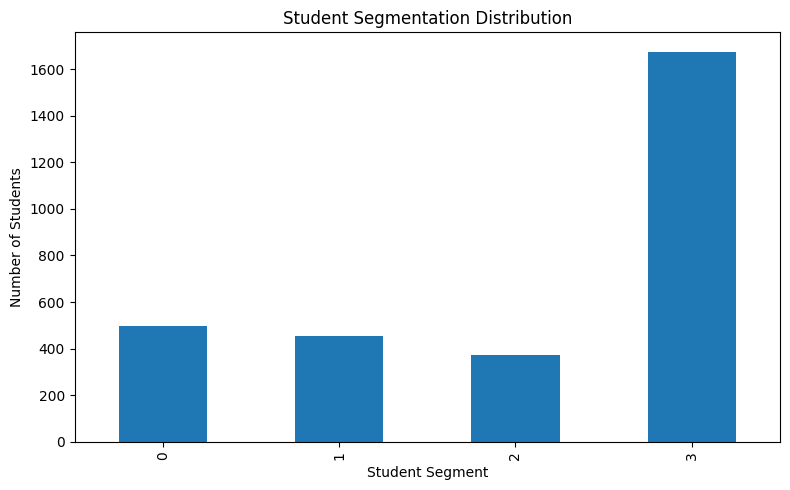

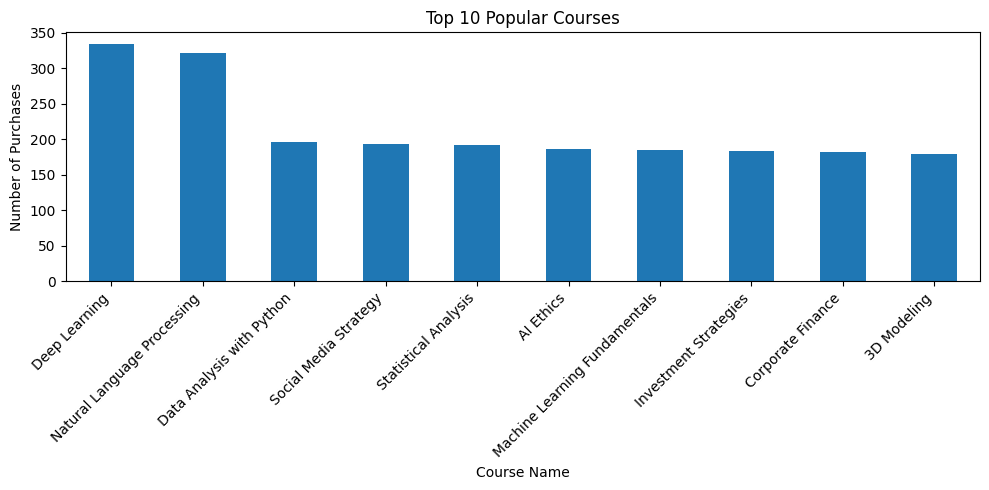

In [12]:
import matplotlib.pyplot as plt

# Student segment distribution
plt.figure(figsize=(8,5))

student_data['Student_Segment'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title('Student Segmentation Distribution')
plt.xlabel('Student Segment')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()

# Top 10 popular courses
top_courses = recommendations.groupby(
    'CourseName'
)['Purchase_Count'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_courses.plot(kind='bar')
plt.title('Top 10 Popular Courses')
plt.xlabel('Course Name')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()